# Практическое занятие № 7 — очистка и преобразование признаков
Учебный кейс: вероятность задержки доставки более 15 минут. Требуется загрузить исходный `orders_dirty.csv`. Рабочая копия не изменяет исходник.

**Правило:** выборки сформированы до вычисления любых обучаемых статистик.

**Особенность данных:** файл из занятия 6 не содержит courier_load, поэтому это поле исключено из входов и числового списка. vehicle_type присутствует, но не включается в заданный набор предикторов. Остальные преобразования сохранены.


In [1]:
# Общая подготовка: одинаковая для практик 7 и 8
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from IPython.display import display
import hashlib
PATH = Path('orders_dirty.csv')
if not PATH.exists():
    raise FileNotFoundError('Загрузите orders_dirty.csv в файлы Colab или измените PATH.')

source_hash = hashlib.sha256(PATH.read_bytes()).hexdigest()
df_raw = pd.read_csv(PATH, encoding='utf-8-sig')
expected = {'order_id','created_at','distance_km','zone','queue_size',
            'weather','promised_minutes','actual_minutes','late'}
missing_cols = expected - set(df_raw.columns)
assert not missing_cols, f'Отсутствуют необходимые поля: {sorted(missing_cols)}'
print('Сырой набор:', df_raw.shape, '; полные дубликаты:', int(df_raw.duplicated().sum()))

# Удаление полных повторов: не обучаем статистику и не используем test.
df = df_raw.drop_duplicates().copy()
df['late'] = pd.to_numeric(df['late'], errors='coerce')
actual = pd.to_numeric(df['actual_minutes'], errors='coerce')
promised = pd.to_numeric(df['promised_minutes'], errors='coerce')
valid_rule = actual.notna() & promised.notna() & df['late'].isin([0, 1])
conflict = valid_rule & (df['late'] != ((actual - promised) > 15).astype(int))
print('Конфликтных меток (проверяемых):', int(conflict.sum()))
df = df.loc[~conflict & df['late'].isin([0, 1])].copy()
df['late'] = df['late'].astype(int)
# Неполные / конфликтные сведения об идентификаторе требуют отдельного решения.
assert df['order_id'].notna().all(), 'Обнаружены пустые ID заказов.'
assert not df['order_id'].duplicated().any(), 'Есть повторные ID: требуется анализ причины, не случайное удаление.'
print('Рабочая копия:', df.shape)

split_path = Path('split_ids_06.csv')  # Необязательный экспорт из практики № 6
# Сохраняем преемственность с выполненной работой № 6.
previous_split = Path('../lb6/06_stratified_splits.csv')
if not split_path.exists() and previous_split.exists():
    previous = pd.read_csv(previous_split, dtype={'order_id': str})
    assert set(previous['order_id']) == set(df['order_id'].astype(str))
    previous[['order_id', 'split']].to_csv(split_path, index=False)
if split_path.exists():
    splits = pd.read_csv(split_path, dtype={'order_id': str})
    splits['split'] = splits['split'].replace({'validation': 'val'})
    assert {'order_id', 'split'} <= set(splits.columns)
    assert set(splits['split']) <= {'train', 'val', 'test'}
    assert splits['order_id'].is_unique
    x = df.assign(order_id=df['order_id'].astype(str)).merge(
        splits[['order_id', 'split']], on='order_id', how='left', validate='one_to_one')
    assert x['split'].notna().all(), 'В split_ids_06.csv перечислены не все рабочие заказы.'
    assert set(splits['order_id']) == set(x['order_id'])
    train = x.loc[x['split'] == 'train'].drop(columns='split').copy()
    val   = x.loc[x['split'] == 'val'].drop(columns='split').copy()
    test  = x.loc[x['split'] == 'test'].drop(columns='split').copy()
else:
    # Воссоздание схемы практики № 6, если файл с IDs не был сохранён.
    train_dev, test = train_test_split(df, test_size=.20, stratify=df['late'], random_state=42)
    train, val = train_test_split(train_dev, test_size=.25,
                                 stratify=train_dev['late'], random_state=42)
    split_export = pd.concat([
       train[['order_id']].assign(split='train'),
       val[['order_id']].assign(split='val'),
       test[['order_id']].assign(split='test')], ignore_index=True)
    split_export.to_csv('split_ids_06.csv', index=False)

sets = [set(a['order_id']) for a in (train, val, test)]
assert len(sets[0]&sets[1]) == len(sets[0]&sets[2]) == len(sets[1]&sets[2]) == 0
assert sets[0]|sets[1]|sets[2] == set(df['order_id'])
assert len(train)+len(val)+len(test) == len(df)
print('train / val / test:', len(train), len(val), len(test))

split_summary = pd.DataFrame([{'subset': label, 'N': len(part),
    'late_n': int(part.late.sum()), 'late_pct': 100*part.late.mean()}
    for label, part in [('train', train), ('val', val), ('test', test)]])
display(split_summary)
split_summary.to_csv('07_split_summary.csv', index=False)


Сырой набор: (600, 10) ; полные дубликаты: 1
Конфликтных меток (проверяемых): 1
Рабочая копия: (598, 10)
train / val / test: 358 120 120


,subset,N,late_n,late_pct
0,train,358,168,46.927374
1,val,120,56,46.666667
2,test,120,56,46.666667


## Этап 1. Создание признаков, которые известны при оформлении заказа
Новый признак `planned_speed_kmh` означает расчётную скорость по известному обещанному времени, **не** фактическую скорость доставки.

In [2]:
# В Colab функция экспортируется в обычный модуль для безопасного joblib.dump.
# При перезапуске блокнота модуль восстанавливается автоматически.
from pathlib import Path
Path('tyumgu_feature_rules.py').write_text("# Правила преобразования признаков для занятий 7–8\nimport numpy as np\nimport pandas as pd\nNUM_BASE = ['distance_km', 'queue_size',  'promised_minutes']\nCAT = ['zone', 'weather']\nNUM = NUM_BASE + ['hour_sin', 'hour_cos', 'planned_speed_kmh']\nINPUT = NUM_BASE + CAT + ['created_at']\n\ndef make_features(X):\n    f = X.loc[:, INPUT].copy()\n    for name in NUM_BASE:\n        f[name] = pd.to_numeric(f[name], errors='coerce')\n    for name in NUM_BASE:\n        f.loc[f[name] < 0, name] = np.nan\n    f.loc[f['promised_minutes'] == 0, 'promised_minutes'] = np.nan\n    for name in CAT:\n        s = f[name].astype('string').str.strip()\n        s = s.mask(s.str.lower().isin(['', 'nan', 'none', 'нет данных', 'неизвестно', 'null']))\n        f[name] = s.astype(object).where(s.notna(), np.nan)\n    time = pd.to_datetime(f['created_at'], errors='coerce')\n    hour = time.dt.hour.astype(float)\n    f['hour_sin'] = np.sin(2*np.pi*hour/24)\n    f['hour_cos'] = np.cos(2*np.pi*hour/24)\n    f['planned_speed_kmh'] = 60*f['distance_km']/f['promised_minutes']\n    f['planned_speed_kmh'] = f['planned_speed_kmh'].replace([np.inf, -np.inf], np.nan)\n    return f.drop(columns='created_at')\n", encoding='utf-8')
from tyumgu_feature_rules import NUM_BASE, NUM, CAT, INPUT, make_features
F_train, F_val, F_test = [make_features(part) for part in (train,val,test)]
assert set(F_train.columns) == set(NUM + CAT)
assert all(col not in F_train.columns for col in ('late','actual_minutes','order_id'))
print('Матрица до кодирования:', F_train.shape)
print('Числовые столбцы:', NUM, '; категориальные:', CAT)

hours = np.array([23, 0, 1])
time_examples = pd.DataFrame({'hour': hours, 'sin': np.sin(2*np.pi*hours/24),
                              'cos': np.cos(2*np.pi*hours/24)})
time_examples['raw_step_from_previous'] = time_examples.hour.diff().abs()
time_examples['cyclic_step_from_previous'] = np.sqrt(
    time_examples['sin'].diff()**2 + time_examples['cos'].diff()**2)
display(time_examples)
time_examples.to_csv('07_time_examples.csv', index=False)


Матрица до кодирования: (358, 8)
Числовые столбцы: ['distance_km', 'queue_size', 'promised_minutes', 'hour_sin', 'hour_cos', 'planned_speed_kmh'] ; категориальные: ['zone', 'weather']


,hour,sin,cos,raw_step_from_previous,cyclic_step_from_previous
0,23,-0.258819,0.965926,NaN,NaN
1,0,0.000000,1.000000,23.0,0.261052
2,1,0.258819,0.965926,1.0,0.261052


## Этап 2. Аудит пропусков и некорректных значений

In [3]:
def missing_report(X, label):
    return pd.DataFrame({'subset': label, 'feature': X.columns, 'N': len(X),
       'missing_n': X.isna().sum().values,
       'missing_pct': (100*X.isna().mean()).round(1).values})
audit = pd.concat([missing_report(F_train,'train'),
                   missing_report(F_val,'val'),
                   missing_report(F_test,'test')], ignore_index=True)
display(audit)
audit.to_csv('07_missing_audit.csv', index=False)
# Уточните по data_dictionary.csv допустимые диапазоны каждой величины.
for col in NUM_BASE:
    print(col, 'train: min=', F_train[col].min(), 'max=', F_train[col].max())
q1, q3 = F_train['distance_km'].quantile([.25,.75])
iqr = q3 - q1
print('IQR:', iqr, 'Границы:', q1-1.5*iqr, q3+1.5*iqr)
print('Среднее/медиана расстояния:', F_train['distance_km'].mean(), F_train['distance_km'].median())

# Описательная статистика и границы выбросов вычисляются только на train.
stats = F_train[NUM].describe().T.rename(columns={'count': 'n', '50%': 'median',
                                                 '25%': 'q1', '75%': 'q3'})
stats['missing_n'] = F_train[NUM].isna().sum()
stats['missing_pct'] = 100*F_train[NUM].isna().mean()
stats['iqr'] = stats.q3 - stats.q1
stats['lower'] = stats.q1 - 1.5*stats.iqr
stats['upper'] = stats.q3 + 1.5*stats.iqr
display(stats)
stats.to_csv('07_train_statistics.csv', index_label='feature')
quality_rows = []
for label, part in [('train', train), ('val', val), ('test', test)]:
    for col in NUM_BASE:
        raw = part[col]
        parsed = pd.to_numeric(raw, errors='coerce')
        quality_rows.append({'subset': label, 'feature': col,
            'raw_missing': int(raw.isna().sum()),
            'parse_errors': int((raw.notna() & parsed.isna()).sum()),
            'negative': int((parsed < 0).sum()),
            'zero_invalid': int((parsed == 0).sum()) if col == 'promised_minutes' else 0,
            'non_integer': int((parsed.notna() & (parsed % 1 != 0)).sum())
                if col in ['queue_size',  'promised_minutes'] else 0})
quality = pd.DataFrame(quality_rows)
display(quality)
quality.to_csv('07_type_audit.csv', index=False)
dictionary = pd.read_csv('data_dictionary.csv')
display(dictionary[dictionary.field.isin(INPUT)][['field', 'allowed_values_or_notes']])
print('queue_size за пределами 0–30 (train):', int((F_train.queue_size > 30).sum()))
print('distance_km вне обычного 0.5–20 (train):',
      int(((F_train.distance_km < .5) | (F_train.distance_km > 20)).sum()))
print('В исходном CSV нет courier_load: отсутствующий признак исключён, значения не выдумываются.')
for col in ['distance_km', 'queue_size']:
    st = stats.loc[col]
    print(f'{col}: среднее={st["mean"]:.3f}, медиана={st["median"]:.3f}, '
          f'диапазон=[{st["min"]:.3f}; {st["max"]:.3f}]. '
          'Медиана сохраняет типичный уровень и устойчива к крайним значениям.')


# Полнота аудита: все исходные поля, включая не используемые в X.
# Фиксированные правила парсинга не обучаются на val/test.
source_audits = []
for label, part in [('train', train), ('val', val), ('test', test)]:
    clean = part.copy()
    for col in ['distance_km', 'queue_size', 'promised_minutes', 'actual_minutes', 'late']:
        clean[col] = pd.to_numeric(clean[col], errors='coerce')
    for col in NUM_BASE:
        clean[col] = make_features(part)[col]
    for col in ['zone', 'weather', 'vehicle_type', 'order_id']:
        if col in clean:
            value = clean[col].astype('string').str.strip()
            clean[col] = value.mask(value.str.lower().isin(
                ['', 'nan', 'none', 'нет данных', 'неизвестно', 'null']))
    clean['created_at'] = pd.to_datetime(clean.created_at, errors='coerce')
    report = missing_report(clean, label)
    report['scope'] = 'source'
    source_audits.append(report)
source_audit = pd.concat(source_audits, ignore_index=True)
derived_audit = audit.loc[audit.feature.isin(['hour_sin', 'hour_cos', 'planned_speed_kmh'])].copy()
derived_audit['scope'] = 'derived'
audit = pd.concat([source_audit, derived_audit], ignore_index=True)
assert set(df_raw.columns) <= set(audit.feature)
display(audit)
audit.to_csv('07_missing_audit.csv', index=False)
category_stats = F_train[CAT].describe().T
category_stats['missing_n'] = F_train[CAT].isna().sum()
category_stats['missing_pct'] = 100*F_train[CAT].isna().mean()
display(category_stats)
category_stats.to_csv('07_category_statistics.csv', index_label='feature')
print('Для категорий среднее, медиана и квартили не определены; показаны число, уникальность и мода.')



,subset,feature,N,missing_n,missing_pct
0,train,distance_km,358,1,0.3
1,train,queue_size,358,1,0.3
2,train,promised_minutes,358,0,0.0
3,train,zone,358,0,0.0
4,train,weather,358,0,0.0
5,train,hour_sin,358,0,0.0
6,train,hour_cos,358,0,0.0
7,train,planned_speed_kmh,358,1,0.3
8,val,distance_km,120,1,0.8
9,val,queue_size,120,0,0.0


distance_km train: min= 1.0 max= 52.8
queue_size train: min= 0.0 max= 22.0
promised_minutes train: min= 21.0 max= 84.0
IQR: 8.399999999999999 Границы: -8.299999999999997 25.299999999999997
Среднее/медиана расстояния: 8.829411764705883 8.5


,n,mean,std,min,q1,median,q3,max,missing_n,missing_pct,iqr,lower,upper
distance_km,357.0,8.829412,5.494558,1.000000,4.300000,8.500000e+00,12.700000,52.800000,1,0.27933,8.400000,-8.300000,25.300000
queue_size,357.0,10.282913,6.257226,0.000000,5.000000,1.000000e+01,16.000000,22.000000,1,0.27933,11.000000,-11.500000,32.500000
promised_minutes,358.0,50.030726,14.667621,21.000000,38.000000,4.950000e+01,62.000000,84.000000,0,0.00000,24.000000,2.000000,98.000000
hour_sin,358.0,-0.029507,0.710337,-1.000000,-0.707107,0.000000e+00,0.707107,1.000000,0,0.00000,1.414214,-2.828427,2.828427
hour_cos,358.0,-0.022551,0.704869,-1.000000,-0.707107,-1.836970e-16,0.707107,1.000000,0,0.00000,1.414214,-2.828427,2.828427
planned_speed_kmh,357.0,9.810967,4.994228,1.783784,6.857143,1.000000e+01,12.626866,73.674419,1,0.27933,5.769723,-1.797441,21.281450


,subset,feature,raw_missing,parse_errors,negative,zero_invalid,non_integer
0,train,distance_km,0,1,0,0,0
1,train,queue_size,1,0,0,0,0
2,train,promised_minutes,0,0,0,0,0
3,val,distance_km,0,1,0,0,0
4,val,queue_size,0,0,0,0,0
5,val,promised_minutes,0,0,0,0,0
6,test,distance_km,0,0,0,0,0
7,test,queue_size,0,0,0,0,0
8,test,promised_minutes,0,0,0,0,0


,field,allowed_values_or_notes
1,created_at,дата должна разбираться
2,distance_km,"обычно 0,5–20; 52,8 требует проверки, но не ав..."
3,queue_size,"0–30, пропуск допустим"
4,weather,"clear, rain, snow; пропуск допустим"
5,zone,"center, north, south, east"
6,promised_minutes,положительное целое


queue_size за пределами 0–30 (train): 0
distance_km вне обычного 0.5–20 (train): 1
В исходном CSV нет courier_load: отсутствующий признак исключён, значения не выдумываются.
distance_km: среднее=8.829, медиана=8.500, диапазон=[1.000; 52.800]. Медиана сохраняет типичный уровень и устойчива к крайним значениям.
queue_size: среднее=10.283, медиана=10.000, диапазон=[0.000; 22.000]. Медиана сохраняет типичный уровень и устойчива к крайним значениям.


,subset,feature,N,missing_n,missing_pct,scope
0,train,order_id,358,0,0.0,source
1,train,created_at,358,0,0.0,source
2,train,distance_km,358,1,0.3,source
3,train,queue_size,358,1,0.3,source
4,train,weather,358,0,0.0,source
5,train,zone,358,0,0.0,source
6,train,promised_minutes,358,0,0.0,source
7,train,actual_minutes,358,0,0.0,source
8,train,late,358,0,0.0,source
9,train,vehicle_type,358,0,0.0,source


,count,unique,top,freq,missing_n,missing_pct
zone,358,4,center,107,0,0.0
weather,358,3,clear,215,0,0.0


Для категорий среднее, медиана и квартили не определены; показаны число, уникальность и мода.


## Этап 3. Импутация только на train; числовое масштабирование
Иллюстрация статистик: нельзя делать `fit_transform` на всей таблице.

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
imputer = SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)
Xn_train = imputer.fit_transform(F_train[NUM])
Xn_val   = imputer.transform(F_val[NUM])
Xn_test  = imputer.transform(F_test[NUM])
scaler = StandardScaler()
Zn_train = scaler.fit_transform(Xn_train)
Zn_val = scaler.transform(Xn_val)
Zn_test = scaler.transform(Xn_test)
print('Числовая матрица:', Zn_train.shape, Zn_val.shape, Zn_test.shape)
print('Медианы, обученные на train:', dict(zip(NUM, imputer.statistics_[:len(NUM)])))
print('Параметры scaler.mean_ (train):', scaler.mean_.round(3))

# Прямое доказательство источника статистик для всех числовых полей.
np.testing.assert_allclose(imputer.statistics_, F_train[NUM].median().to_numpy())
np.testing.assert_allclose(scaler.mean_, Xn_train.mean(axis=0))
np.testing.assert_allclose(scaler.var_, Xn_train.var(axis=0))
fitted_before = (imputer.statistics_.copy(), scaler.mean_.copy(), scaler.scale_.copy())
probe_numeric = F_val[NUM].copy()
probe_numeric['distance_km'] = 10**9
scaler.transform(imputer.transform(probe_numeric))
for old, new in zip(fitted_before, [imputer.statistics_, scaler.mean_, scaler.scale_]):
    np.testing.assert_array_equal(old, new)
parameters = pd.DataFrame({'feature': imputer.get_feature_names_out(NUM),
                          'scaler_mean': scaler.mean_, 'scaler_scale': scaler.scale_})
parameters['imputer_median'] = list(imputer.statistics_) + [np.nan]*(len(parameters)-len(NUM))
display(parameters)
parameters.to_csv('07_transform_parameters.csv', index=False)
# Собственный индикатор равен автоматически сформированному, в том числе после scaling.
indicator_index = list(imputer.get_feature_names_out(NUM)).index('missingindicator_distance_km')
for F, Xn, Zn in [(F_train, Xn_train, Zn_train), (F_val, Xn_val, Zn_val), (F_test, Xn_test, Zn_test)]:
    own = F.distance_km.isna().astype(int).to_numpy()
    np.testing.assert_array_equal(own, Xn[:, indicator_index])
    own_scaled = (own - scaler.mean_[indicator_index])/scaler.scale_[indicator_index]
    np.testing.assert_allclose(own_scaled, Zn[:, indicator_index])
print('Собственный индикатор совпадает с автоматическим на всех трёх выборках; дубликат не добавляем.')
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler().fit(Xn_train)
print('StandardScaler distance: mean/scale =', scaler.mean_[0], scaler.scale_[0])
print('MinMaxScaler distance: min/max =', minmax.data_min_[0], minmax.data_max_[0])


indicator_comparison = []
for label, F, Xn in [('train', F_train, Xn_train), ('val', F_val, Xn_val), ('test', F_test, Xn_test)]:
    custom = F.assign(distance_missing_custom=F.distance_km.isna().astype(int))
    own = custom['distance_missing_custom'].to_numpy()
    indicator_comparison.append({'subset': label, 'N': len(F),
        'custom_missing_n': int(own.sum()),
        'automatic_missing_n': int(Xn[:, indicator_index].sum()),
        'mismatch_n': int(np.count_nonzero(own != Xn[:, indicator_index]))})
indicator_comparison = pd.DataFrame(indicator_comparison)
assert indicator_comparison.mismatch_n.eq(0).all()
display(indicator_comparison)
indicator_comparison.to_csv('07_indicator_comparison.csv', index=False)



Числовая матрица:

 (358, 9) (120, 9) (120, 9)
Медианы, обученные на train: {'distance_km': np.float64(8.5), 'queue_size': np.float64(10.0), 'promised_minutes': np.float64(49.5), 'hour_sin': np.float64(0.0), 'hour_cos': np.float64(-1.8369701987210297e-16), 'planned_speed_kmh': np.float64(10.0)}
Параметры scaler.mean_ (train): [ 8.8280e+00  1.0282e+01  5.0031e+01 -3.0000e-02 -2.3000e-02  9.8110e+00
  3.0000e-03  3.0000e-03  3.0000e-03]


,feature,scaler_mean,scaler_scale,imputer_median
0,distance_km,8.828492,5.479217,8.500000e+00
1,queue_size,10.282123,6.239741,1.000000e+01
2,promised_minutes,50.030726,14.647121,4.950000e+01
3,hour_sin,-0.029507,0.709344,0.000000e+00
4,hour_cos,-0.022551,0.703883,-1.836970e-16
5,planned_speed_kmh,9.811495,4.980269,1.000000e+01
6,missingindicator_distance_km,0.002793,0.052778,NaN
7,missingindicator_queue_size,0.002793,0.052778,NaN
8,missingindicator_planned_speed_kmh,0.002793,0.052778,NaN


Собственный индикатор совпадает с автоматическим на всех трёх выборках; дубликат не добавляем.
StandardScaler distance: mean/scale = 8.828491620111732 5.479216543075062
MinMaxScaler distance: min/max = 1.0 52.8


,subset,N,custom_missing_n,automatic_missing_n,mismatch_n
0,train,358,1,1,0
1,val,120,1,1,0
2,test,120,0,0,0


## Этап 4. One-Hot кодирование; неизвестные категории

In [5]:
cat_imp = SimpleImputer(strategy='constant', fill_value='неизвестно')
C_train = cat_imp.fit_transform(F_train[CAT])
C_val = cat_imp.transform(F_val[CAT]); C_test = cat_imp.transform(F_test[CAT])
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
O_train = ohe.fit_transform(C_train)
O_val = ohe.transform(C_val); O_test = ohe.transform(C_test)
print('Категории, обнаруженные исключительно в train:', ohe.categories_)
print('После кодирования:', O_train.shape, O_val.shape, O_test.shape)
print('Имена категориальных столбцов:', list(ohe.get_feature_names_out(CAT)))
# Проверка незнакомого значения: не переобучаем OHE
probe = C_val[:1].copy()
if len(probe):
    probe[0,0] = '__НОВАЯ_ЗОНА__'
    assert ohe.transform(probe).shape[1] == O_train.shape[1]

zone_width = len(ohe.categories_[0])
encoded_probe = ohe.transform(probe)
assert np.count_nonzero(encoded_probe[0, :zone_width]) == 0
np.testing.assert_array_equal(encoded_probe[0, zone_width:], O_val[0, zone_width:])
print('Новая зона даёт нули в блоке zone:', encoded_probe[0, :zone_width])
print('Поля weather и размерность сохранены. Сведения о новой зоне теряются.')
ohe_schema = pd.DataFrame({'feature': ohe.get_feature_names_out(CAT),
    'source': [col for col, categories in zip(CAT, ohe.categories_) for _ in categories]})
display(ohe_schema)
ohe_schema.to_csv('07_ohe_schema.csv', index=False)
print(f'До One-Hot: {len(CAT)} категориальных поля; после: {O_train.shape[1]}.')


Категории, обнаруженные исключительно в train: [array(['center', 'east', 'north', 'south'], dtype=object), array(['clear', 'rain', 'snow'], dtype=object)]
После кодирования: (358, 7) (120, 7) (120, 7)
Имена категориальных столбцов: ['zone_center', 'zone_east', 'zone_north', 'zone_south', 'weather_clear', 'weather_rain', 'weather_snow']
Новая зона даёт нули в блоке zone: [0. 0. 0. 0.]
Поля weather и размерность сохранены. Сведения о новой зоне теряются.


,feature,source
0,zone_center,zone
1,zone_east,zone
2,zone_north,zone
3,zone_south,zone
4,weather_clear,weather
5,weather_rain,weather
6,weather_snow,weather


До One-Hot: 2 категориальных поля; после: 7.


## Этап 5. Формирование готовой матрицы; графики и сохранение результатов

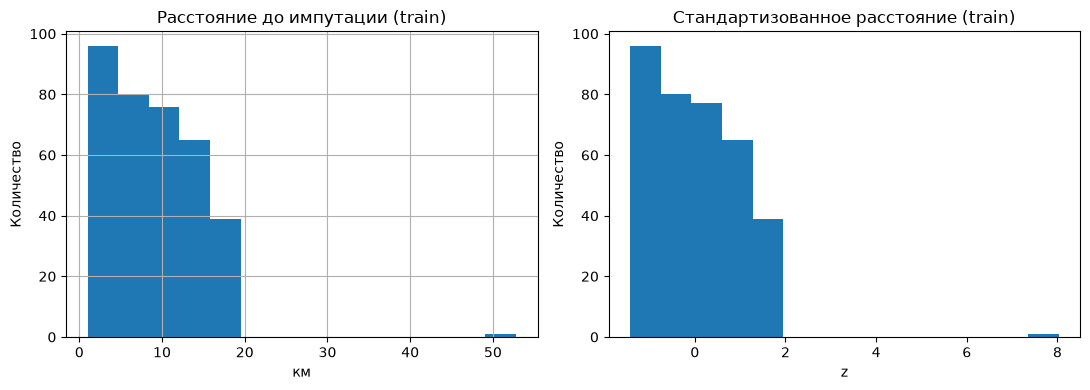

Сохранены: 07_missing_audit.csv, 07_feature_schema.csv, 07_X_train.csv, 07_scaling.png


,stage,columns
0,Входные поля,6
1,После конструирования,8
2,Числовые с индикаторами,9
3,One-Hot,7
4,Итог,16


Исходный CSV не изменён, проверки пройдены.


In [6]:
import matplotlib.pyplot as plt
names = [*imputer.get_feature_names_out(NUM), *ohe.get_feature_names_out(CAT)]
M_train = np.column_stack([Zn_train, O_train])
M_val = np.column_stack([Zn_val, O_val])
M_test = np.column_stack([Zn_test, O_test])
assert M_train.shape[1] == M_val.shape[1] == M_test.shape[1] == len(names)
assert np.isfinite(M_train).all() and np.isfinite(M_val).all() and np.isfinite(M_test).all()
pd.DataFrame({'feature_name':names}).to_csv('07_feature_schema.csv',index=False)
# Матричные экспорты технические, не включайте метку y внутрь X.
pd.DataFrame(M_train,columns=names).to_csv('07_X_train.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11,4))
F_train['distance_km'].dropna().hist(ax=ax[0],bins=14)
ax[0].set(title='Расстояние до импутации (train)',xlabel='км',ylabel='Количество')
ax[1].hist(Zn_train[:,0],bins=14)
ax[1].set(title='Стандартизованное расстояние (train)',xlabel='z',ylabel='Количество')
plt.tight_layout(); plt.savefig('07_scaling.png',dpi=150); plt.show()
print('Сохранены: 07_missing_audit.csv, 07_feature_schema.csv, 07_X_train.csv, 07_scaling.png')

for label, matrix, part in [('train', M_train, train), ('val', M_val, val), ('test', M_test, test)]:
    pd.DataFrame(matrix, columns=names).to_csv(f'07_X_{label}.csv', index=False)
    part[['order_id', 'late']].to_csv(f'07_y_{label}.csv', index=False)
dimensions = pd.DataFrame({'stage': ['Входные поля', 'После конструирования',
    'Числовые с индикаторами', 'One-Hot', 'Итог'],
    'columns': [len(INPUT), F_train.shape[1], Zn_train.shape[1], O_train.shape[1], M_train.shape[1]]})
display(dimensions)
dimensions.to_csv('07_dimensions.csv', index=False)
assert hashlib.sha256(PATH.read_bytes()).hexdigest() == source_hash
print('Исходный CSV не изменён, проверки пройдены.')


# Проверка сохранённых файлов, включая выравнивание X и y по строкам.
for label, matrix, part in [('train', M_train, train), ('val', M_val, val), ('test', M_test, test)]:
    saved_X = pd.read_csv(f'07_X_{label}.csv')
    saved_y = pd.read_csv(f'07_y_{label}.csv')
    assert list(saved_X.columns) == names
    assert not {'late', 'actual_minutes', 'order_id'} & set(saved_X.columns)
    assert saved_y.order_id.tolist() == part.order_id.tolist()
    np.testing.assert_array_equal(saved_y.late.to_numpy(), part.late.to_numpy())
    np.testing.assert_allclose(saved_X.to_numpy(), matrix, atol=1e-14)



## Самостоятельная проверка
1. Сравните среднее и медиану `distance_km`. Объясните выбор импутации.
2. Сравните число признаков до и после One-Hot.
3. Для любого признака докажите, что статистика импутации и `scaler.mean_` взяты только из train.
4. Проверьте, почему значение «__НОВАЯ_ЗОНА__» не вызывает ошибку.
5. Добавьте собственный индикатор отсутствия `distance_km` и сравните результаты.

**Результат:** файл блокнота, отчёт, схемы и таблицы; исходный CSV не перезаписывать.

### Ответы и выводы

1. Среднее и медиана расстояния, а также очереди сопоставлены в этапе 2. Для расстояния редкие большие значения сдвигают среднее; медиана устойчива к ним. Для очереди медиана характеризует типичное число заказов и также меньше зависит от крайних нагрузок. IQR служит сигналом для проверки, а не доказательством ошибки. Значения не удаляются автоматически.
2. Полные списки One-Hot и итоговых признаков сохранены в `07_ohe_schema.csv` и `07_feature_schema.csv`; размеры на каждом шаге приведены в `07_dimensions.csv`. Индикаторы пропусков тоже увеличивают число столбцов.
3. На этапе 3 медианы напрямую сверены с `F_train[NUM].median()`, а средние и дисперсии scaler — с импутированной train-матрицей. Изменение validation до 10⁹ не меняет обученные параметры при `transform`.
4. `handle_unknown='ignore'` кодирует новую зону нулевым блоком zone; блок weather и число столбцов остаются прежними. Новая зона не получает собственного признака, поэтому информация о её специфике теряется.
5. Собственный индикатор `distance_km.isna().astype(int)` совпал с `missingindicator_distance_km` на train, val и test; совпали и стандартизованные значения. Добавление его второй раз лишь дублировало бы признак, поэтому в итоговой матрице оставлена одна копия.

**Время суток.** У простого часа расстояния между 23 и 0, 0 и 1 равны 23 и 1. У пары sin/cos оба расстояния около 0,261: переход через полночь корректно сохраняет соседство. Это сравнение представлений, обучение модели в работе не требуется.

**Три ошибки подготовки.** Импутация до разделения переносит сведения о validation/test в обучение и искажает независимую оценку. Отдельный fit One-Hot на каждой выборке меняет смысл или число столбцов. Добавление actual_minutes создаёт прямую утечку будущего результата: при оформлении заказа его ещё нет.

**Контрольные вопросы.**
- Среднее всей таблицы зависит от отложенных объектов, поэтому даже без их меток нарушает независимость проверки.
- Границы IQR зависят от распределения и могут отмечать корректные редкие дальние заказы; решение требует предметных оснований.
- StandardScaler вычитает среднее train и делит на стандартное отклонение train (после импутации). MinMaxScaler использует минимум и размах train; постоянный столбец обрабатывается библиотекой без деления на ноль. Значения test могут выходить за [0, 1], а z-оценка вообще не ограничена этим интервалом.
- Два категориальных поля заменяются суммой чисел категорий, найденных в train, включая константу для пропуска, если она встретилась.
- actual_minutes доступен после доставки и участвует в определении y, поэтому его нельзя использовать в X при прогнозе на момент создания.
- 23:00 и 00:00 разделены одним часом; циклические координаты устраняют искусственный скачок.

**Вывод.** Подготовлена рабочая копия с проверкой исторической метки и уникальности ID. Разбиение выполнено до оценки статистик преобразования. Некорректные типы приведены к пропускам по фиксированным правилам. Числовые пропуски заменены медианами train, а категории — константой. Масштабирование и One-Hot обучены исключительно на train, что подтверждено проверками. Циклическое время и плановая скорость доступны при создании заказа и не используют фактическую длительность. Получены конечные числовые матрицы одинаковой ширины без изменения исходного CSV.
